# Graphs and reinforcement learning

http://mnemstudio.org/path-finding-q-learning-tutorial.htm

http://firsttimeprogrammer.blogspot.com/2016/09/getting-ai-smarter-with-q-learning.html

https://amunategui.github.io/reinforcement-learning/index.html

In [139]:
import pandas as pd
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

FS = 15

In [1123]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

# Make a simple graph

In [740]:
def draw_graph(graph, start=None, goal=None, route=None):
    pos = nx.spring_layout(graph)
    nx.draw_networkx_nodes(graph, pos)
    nx.draw_networkx_edges(graph, pos)
    nx.draw_networkx_labels(graph, pos, font_color='w')
    if start:
        nx.draw_networkx_nodes(graph, pos, nodelist=[start], node_color='g')
    if goal:
        nx.draw_networkx_nodes(graph, pos, nodelist=[goal], node_color='r')
    if route:
        route = get_edges_from_nodes(route)
        kwargs = dict(edge_color='r', width=3, style='solid', alpha=0.7)
        nx.draw_networkx_edges(graph, pos, edgelist=route, **kwargs)
    plt.show()

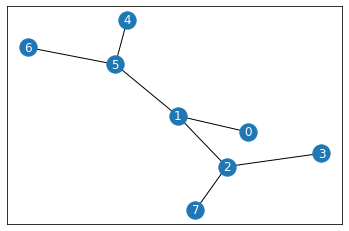

In [741]:
# Make the graph
points_list = [(0, 1), (1, 5), (5, 6), (5, 4), (1, 2), (2, 3), (2, 7)]
G = nx.Graph()
G.add_edges_from(points_list)
draw_graph(G)

### Create the reward graph

In [715]:
MATRIX_SIZE = len(G.nodes)
R = -1 * np.matrix(np.ones(shape=(MATRIX_SIZE, MATRIX_SIZE)))

# assign zeros to paths and 100 to goal-reaching point
goal = 7
for point in points_list:
    print(point)
    R[point] = 100 if point[1] == goal else 0    
    R[point[::-1]] = 100 if point[0] == goal else 0

# add goal point round trip
R[goal, goal]= 100

(0, 1)
(1, 5)
(5, 6)
(5, 4)
(1, 2)
(2, 3)
(2, 7)


# Set up the Q-learning

In [725]:
def get_available_actions(state):
    current_state_row = R[state, ]
    return np.where(current_state_row >= 0)[1]

def sample_next_action(actions):
    return int(np.random.choice(actions, 1))

def get_edges_from_nodes(nodes):
    edges = []
    for i in range(len(nodes) - 1):
        edges.append(tuple(nodes[i:i + 2]))
    return edges

def update(current_state, action, gamma):
    max_idx = np.where(Q[action, ] == np.max(Q[action, ]))[1]
    
    if max_idx.shape[0] > 1:
        max_idx = int(np.random.choice(max_idx, size=1))
    else:
        max_idx = int(max_idx)
    max_value = Q[action, max_idx]
    
    Q[current_state, action] = R[current_state, action] + gamma * max_value
    return (np.sum(Q / np.max(Q) * 100)) if (np.max(Q) > 0) else (0)

## Train the model

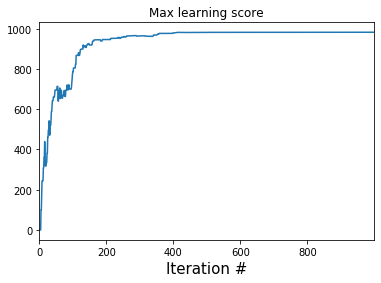

Trained Q matrix:
[[  0.  64.   0.   0.   0.   0.   0.   0.]
 [ 51.   0.  80.   0.   0.  51.   0.   0.]
 [  0.  64.   0.  64.   0.   0.   0. 100.]
 [  0.   0.  80.   0.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.  51.   0.   0.]
 [  0.  64.   0.   0.  40.   0.  40.   0.]
 [  0.   0.   0.   0.   0.  51.   0.   0.]
 [  0.   0.  80.   0.   0.   0.   0. 100.]]


In [717]:
# Initialize the "brain" matrix
Q = np.matrix(np.zeros([MATRIX_SIZE, MATRIX_SIZE]))

# Set the learning parameter
gamma = 0.8

# Training
scores = []
for i in range(1000):
    current_state = np.random.randint(0, MATRIX_SIZE)
    available_actions = get_available_actions(current_state)
    action = sample_next_action(available_actions)
    score = update(current_state, action, gamma)
    scores.append(score)
ax = pd.Series(scores).plot(title='Max learning score')
ax.set_xlabel('Iteration #', fontsize=FS)
plt.show()
    
print("Trained Q matrix:")
Q = 100 * Q / np.max(Q)
print(10 * Q // 10)

### Test the model

In [718]:
def find_next_step(current_state):
    max_val = np.max(Q[current_state, ])
    viable_states = R[current_state] >= 0
    return np.where((Q[current_state] == max_val) & viable_states)[1]

Most efficient path: [6, 5, 1, 2, 7]


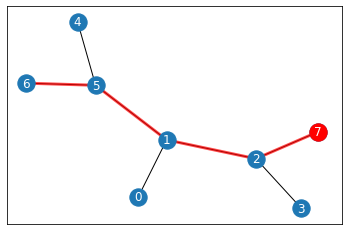

In [719]:
initial_state = 6
current_state = initial_state
steps = [current_state]
while current_state != goal:
    next_step_index = find_next_step(current_state)
    
    if next_step_index.shape[0] > 1:
        next_step_index = np.random.choice(next_step_index, size=1)
    next_step_index = int(next_step_index)
    
    steps.append(next_step_index)
    current_state = next_step_index

print(f"Most efficient path: {steps}")
draw_graph(G, goal=goal, route=steps)

# Make a Fill Or Bust graph

In [2]:
def get_edge_list_from_dict(edge_dict):
    edge_list = []
    for key, val in edge_dict.items():
        edge_list.extend([(key, node) for node in val])
    return edge_list

In [1726]:
edge_dict = {'DRAW': ['ROLL', 'BUST'],
             'ROLL': ['HOLD', 'BUST'],
             'HOLD': ['ROLL', 'STOP', 'FILL'],
             'FILL': ['DRAW', 'STOP'],
             'BUST': ['DRAW']}
G = nx.DiGraph()
G.add_edges_from(get_edge_list_from_dict(edge_dict))

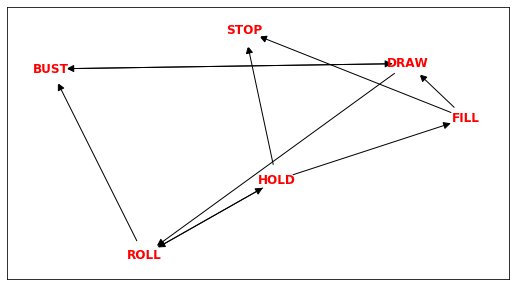

In [1727]:
fig, ax = plt.subplots(figsize=(9, 5))
kwargs = dict(arrowsize=15,
              node_size=1000,
              node_color='w',
              font_weight='heavy',
              font_color='r')
# pos = nx.spring_layout(G, iterations=5)
nx.draw_networkx(G, pos=pos, ax=ax, **kwargs)
plt.show()

### Create the reward graph

### Simple dice model

In [2089]:
class Turn(object):
    from collections import Counter
    
    def __init__(self):
        self.score = 0
        self.status = 'DRAW'
        self.num_pointers = 0
        self.dice_remaining = 6
        self.turn_in_progress = True
                
    def draw(self):
        if not self.turn_in_progress:
            self.__init__()
        card = np.random.choice(np.array(9 * [True] + [False]))
        return 'ROLL' if card else 'BUST'

    def roll(self):
        # Roll the dice
        dice = np.sort(np.random.randint(1, 7, self.dice_remaining))
        
        # Count the pointers
        counts = np.array([Counter(dice)[k] for k in range(1, 7)])
        roll_score = np.dot(counts, np.array([100, 0, 0, 0, 50, 0]))
        
        # Keep track of remaining dice and total score
        self.num_pointers = np.dot(counts, np.array([1, 0, 0, 0, 1, 0]))
        self.dice_remaining -= self.num_pointers
        self.score += roll_score
        
        # Determine next state based on dice roll
        if roll_score == 0:
            self.score = 0
            return 'BUST'
        if self.dice_remaining == 0:
            return 'FILL'
        return 'HOLD'
    
    def take_action(self, action):
        '''Takes an action, returns the resulting state.'''
        if action == 'DRAW':
            self.status, score = [self.draw()], 0
        if action == 'ROLL':
            self.status, score = [self.roll()], 0
        if action == 'HOLD':
            self.status, score = ['ROLL', 'STOP'], 0
        if action == 'FILL':
            self.status, score = ['DRAW', 'STOP'], 0
        if action == 'BUST':
            self.status, score = ['DRAW'], -10
        if action == 'STOP':
            self.status, score = ['DRAW'], self.score
        if action in ['BUST', 'STOP']:
            self.turn_in_progress = False
        return self.status, score
    
    def __repr__(self):
        return f'<Turn> Status: {self.status}, Score: {self.score}, Dice remaining: {self.dice_remaining}'

In [2041]:
turn = Turn()
turn

<Turn> Status: DRAW, Score: 0, Dice remaining: 6

#### Make the graph

In [1728]:
G = nx.convert_node_labels_to_integers(G, label_attribute='label')
d = pd.DataFrame([G.nodes[node] for node in G.nodes])['label']
label_to_int = dict(zip(d.values, d.index))
int_to_label = dict(zip(label_to_int.values(), label_to_int.keys()))
label_to_int

{'DRAW': 0, 'ROLL': 1, 'BUST': 2, 'HOLD': 3, 'STOP': 4, 'FILL': 5}

In [1773]:
MATRIX_SIZE = len(G.nodes)
R = -1 * np.matrix(np.ones(shape=(MATRIX_SIZE, MATRIX_SIZE)))

# assign zeros to paths and 100 to goal-reaching point
goal = label_to_int['FILL']
point_list = list(G.edges)
for point in point_list:
    R[point] = 0

# add goal point round trip
# R[goal, goal]= 100
R

matrix([[-1.,  0.,  0., -1., -1., -1.],
        [-1., -1.,  0.,  0., -1., -1.],
        [ 0., -1., -1., -1., -1., -1.],
        [-1.,  0., -1., -1.,  0.,  0.],
        [-1., -1., -1., -1., -1., -1.],
        [ 0., -1., -1., -1.,  0., -1.]])

In [1774]:
# State transition matrix
P = np.zeros((MATRIX_SIZE, MATRIX_SIZE))
P[0, ] = [0.0, 0.8, 0.2, 0.0, 0.0, 0.0]
P[1:, ] = (1 / MATRIX_SIZE)
print(P)

[[0.         0.8        0.2        0.         0.         0.        ]
 [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]
 [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]
 [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]
 [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]
 [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]]


## Train the model

In [1669]:
def get_available_actions(state):
    current_state_row = R[state, ]
    return np.where(current_state_row >= 0)[1]

def sample_next_action(actions):
    return int(np.random.choice(actions, 1))

def normalize(x):
    if len(set(x)):
        return np.array(len(x) * [1 / len(x)])
    return (x - min(x)) / (max(x) - min(x))

In [2119]:
def update(current_state, action, gamma):
    max_idx = np.where(Q[action, ] == np.max(Q[action, ]))[1]
    if max_idx.shape[0] > 1:
        max_idx = np.random.choice(max_idx, size=1)
    max_value = Q[action, max_idx]
    
    action_label = int_to_label[action]
    Q[current_state, action] = turn.take_action(action_label)[1] + gamma * max_value
    return (np.sum(Q / np.max(Q) * 100)) if (np.max(Q) > 0) else (0)

(    0 / 10000)
( 1000 / 10000)
( 2000 / 10000)
( 3000 / 10000)
( 4000 / 10000)
( 5000 / 10000)
( 6000 / 10000)
( 7000 / 10000)
( 8000 / 10000)
( 9000 / 10000)


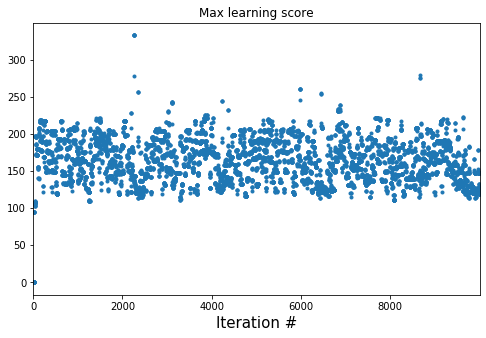

Trained Q matrix:
[[  0.   1.  -5.   0.   0.   0.]
 [  0.   0.  -5.  10.   0.   2.]
 [  0.   0.   0.   0.   0.   0.]
 [  0.   1.   0.   0. 100.   0.]
 [  0.   0.   0.   0.   0.   0.]
 [  0.   0.   0.   0.  25.   0.]]


In [2123]:
# Initialize the "brain" matrix
Q = np.matrix(np.zeros([MATRIX_SIZE, MATRIX_SIZE]))

# Set the learning parameter
gamma = 0.1

# Training
turn = Turn() # Start a new turn (?)
scores = []
current_state = 'DRAW'
N = 10000
for i in range(N):
    if i % 1000 == 0:
        print(f'({i:5.0f} / {N})')
    actions = turn.take_action(current_state)[0]
    action = np.random.choice(actions) if len(actions) > 1 else actions[0]
    score = update(label_to_int[current_state],
                   label_to_int[action],
                   gamma)
    scores.append(score)
    current_state = action
# Plot the max score over time
ax = pd.Series(scores).plot(title='Max learning score', style='.', figsize=(8, 5))
ax.set_xlabel('Iteration #', fontsize=FS)
plt.show()
    
print("Trained Q matrix:")
Qnorm = 100 * Q / np.max(Q)
print(10 * Qnorm // 10)

In [2075]:
int_to_label

{0: 'DRAW', 1: 'ROLL', 2: 'BUST', 3: 'HOLD', 4: 'STOP', 5: 'FILL'}

### Test the model

In [2124]:
def find_next_step(current_state):
    max_val = np.max(Q[current_state, ])
    viable_states = R[current_state] >= 0
    return np.where((Q[current_state] == max_val) & viable_states)[1]

In [2125]:
goal = 'STOP'
initial_state = 'DRAW'
current_state = initial_state
steps = [current_state]
n = -1
while current_state != goal and n < 1000:
    n += 1
    next_step_index = find_next_step(label_to_int[current_state])
    
    if next_step_index.shape[0] > 1:
        next_step_index = np.random.choice(next_step_index, size=1)
    next_step_index = int(next_step_index)
    
    steps.append(int_to_label[next_step_index])
    current_state = steps[-1]

print(f"Most efficient path: {steps}")

Most efficient path: ['DRAW', 'ROLL', 'HOLD', 'STOP']
